# Waveform Classification

A synthetic benchmark from the classic CART book (Breiman et al., 1984): each sample is a wave sampled at **21 positions**, built by combining two of three triangular base waves and adding noise. There are **3 classes**, each a different combination. Because the classes overlap by construction, even the best possible classifier cannot reach 100% — the Bayes error rate here is about 14%.


In [1]:
import io, urllib.request, zipfile, gzip
import numpy as np
import pandas as pd

def download(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req, timeout=180) as r:
        return r.read()
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report

# UCI serves this dataset as a ready CSV at the dataset's data_url (the original .Z files are LZW-compressed)
df = pd.read_csv(io.BytesIO(download('https://archive.ics.uci.edu/static/public/107/data.csv')))
print(df.shape)
df.head(3)

(5000, 22)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,Attribute21,class
0,-1.23,-1.56,-1.75,-0.28,0.60,2.22,0.85,0.21,-0.20,0.89,...,2.89,7.75,4.59,3.15,5.12,3.32,1.20,0.24,-0.56,2
1,-0.69,2.43,0.61,2.08,2.30,3.25,5.52,4.55,2.97,2.22,...,1.24,1.89,1.88,-1.34,0.83,1.41,1.78,0.60,2.42,1
2,-0.12,-0.94,1.29,2.59,2.42,3.55,4.94,3.25,1.90,2.07,...,2.50,0.12,1.41,2.78,0.64,0.62,-0.01,-0.79,-0.12,0


In [2]:
X = df.drop(columns=['class']); y = df['class']
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(Xtr, ytr)
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
print(f'Random Forest accuracy: {accuracy_score(yte, rf.predict(Xte)):.4f}')
print(f'Logistic Regression accuracy: {accuracy_score(yte, lr.predict(Xte)):.4f}')
print(classification_report(yte, rf.predict(Xte)))

Random Forest accuracy: 0.8480
Logistic Regression accuracy: 0.8680
              precision    recall  f1-score   support

           0       0.88      0.78      0.82       414
           1       0.83      0.86      0.85       412
           2       0.84      0.91      0.87       424

    accuracy                           0.85      1250
   macro avg       0.85      0.85      0.85      1250
weighted avg       0.85      0.85      0.85      1250



Attribute11    0.101487
Attribute15    0.090681
Attribute7     0.079706
Attribute6     0.071527
Attribute12    0.068415
Attribute10    0.065621
Attribute5     0.064411
Attribute13    0.059829
Attribute16    0.051016
Attribute17    0.050280
Attribute9     0.049933
Attribute8     0.048342
Attribute14    0.040967
Attribute18    0.033765
Attribute4     0.027509
Attribute19    0.019770
Attribute3     0.018268
Attribute20    0.015511
Attribute2     0.015450
Attribute1     0.014043
Attribute21    0.013469
dtype: float64


<Axes: title={'center': 'Which waveform positions matter?'}>

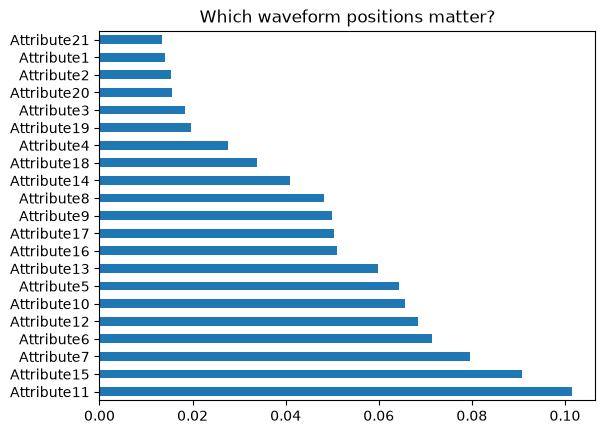

In [3]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)
imp.plot(kind='barh', title='Which waveform positions matter?')